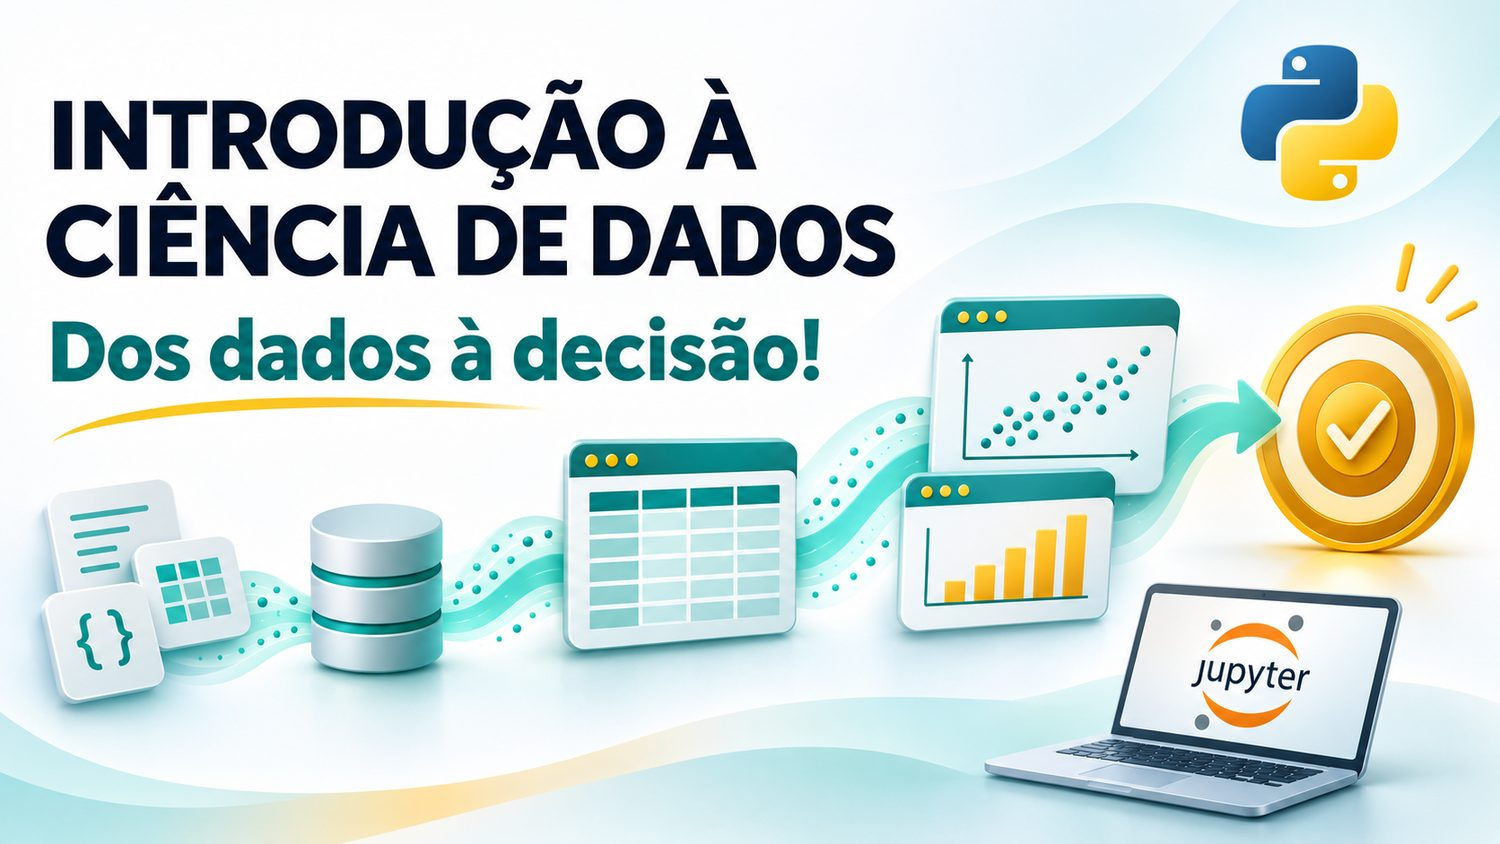

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_2_fontes_tipos_estruturas/03_Estruturas_e_Formatos.ipynb)

# Capítulo 3 – Estruturas e formatos

Sabemos de onde vêm os dados e o que significam os valores. Falta organizá-los de forma que muitas observações possam ser comparadas e usadas. Este capítulo percorre os três graus de organização (dados estruturados, semiestruturados e não estruturados), mostra o mesmo registo em vários formatos e ensina a levar cada um até uma tabela.

> **Objetivos:** distinguir dados estruturados, semiestruturados e não estruturados; definir e verificar um esquema; ler CSV, JSON, XML e HTML e convertê-los em tabelas; tomar decisões sobre campos aninhados; extrair variáveis de texto livre; comparar vantagens e desvantagens de cada organização.

**Pré-requisitos:** capítulos 1 e 2 deste módulo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_padaria(semente=7):
    """Gera os dados de uma cadeia fictícia de padarias (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    lojas = pd.DataFrame({
        "loja_id": ["0041", "0042", "0043", "0107", "0212", "0305"],
        "zona": ["Baixa", "Baixa", "Ribeira", "Estação", "Universidade", "Mercado"],
        "producao_habitual": [320, 260, 180, 400, 220, 300]})
    dias = pd.date_range("2026-03-02", periods=84, freq="D")          # doze semanas, de segunda a domingo
    chuva = np.where(rng.random(84) < 0.35, rng.gamma(2.0, 3.0, 84).round(1), 0.0)
    meteo = pd.DataFrame({"data": dias, "chuva_mm": chuva})
    eventos = pd.DataFrame({
        "data": pd.to_datetime(["2026-03-14", "2026-03-28", "2026-04-11", "2026-04-25", "2026-05-09", "2026-05-16"]),
        "zona": ["Ribeira", "Mercado", "Baixa", "Baixa", "Ribeira", "Universidade"],
        "evento": ["Feira do livro", "Mercado de produtores", "Maratona", "Desfile", "Festival de rua", "Dia aberto"]})
    fator_dia = [0.95, 0.90, 0.92, 0.97, 1.06, 1.20, 1.08]            # segunda a domingo
    linhas = []
    for loja in lojas.itertuples():
        for dia, mm in zip(dias, chuva):
            ha_evento = ((eventos["data"] == dia) & (eventos["zona"] == loja.zona)).any()
            procura = (loja.producao_habitual * 0.9 * fator_dia[dia.dayofweek] * (1 - 0.012 * mm)
                       * (1.35 if ha_evento else 1.0) * rng.normal(1.0, 0.07))
            linhas.append((loja.loja_id, dia, loja.producao_habitual, int(min(round(procura), loja.producao_habitual))))
    vendas = pd.DataFrame(linhas, columns=["loja_id", "data", "produzidos", "vendidos"])
    return lojas, vendas, meteo, eventos


lojas, vendas, meteo, eventos = gerar_padaria()
vendas.head()

,loja_id,data,produzidos,vendidos
0,0041,2026-03-02,320,260
1,0041,2026-03-03,320,250
2,0041,2026-03-04,320,290
3,0041,2026-03-05,320,253
4,0041,2026-03-06,320,253


## Três graus de organização

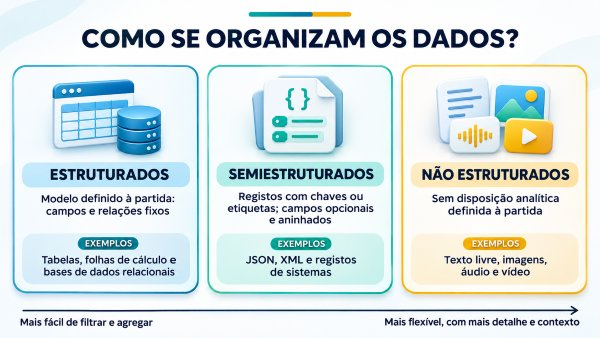

Os três graus não são gavetas estanques, são um contínuo. E dizem respeito à **organização**, não ao conteúdo: uma tabela estruturada pode conter quantidades, categorias, datas e até texto.

## Dados estruturados

Dados **estruturados** seguem um modelo definido à partida, com campos identificáveis e relações entre eles. A forma mais comum é a tabela.

In [3]:
vendas.head(3)

,loja_id,data,produzidos,vendidos
0,0041,2026-03-02,320,260
1,0041,2026-03-03,320,250
2,0041,2026-03-04,320,290


Numa tabela bem construída:

- cada **linha** é uma observação. Aqui: uma loja num dia. É a unidade de análise do módulo 1.
- cada **coluna** é uma variável;
- cada **célula** tem um único valor.

### O esquema

O **esquema** (*schema*) é a descrição da tabela: os nomes dos campos, os seus tipos e as regras que os valores têm de cumprir. É o contrato entre quem produz os dados e quem os usa.

| Campo | Tipo | Regra |
| --- | --- | --- |
| `loja_id` | texto | quatro algarismos; existe no cadastro das lojas |
| `data` | data | não pode estar no futuro |
| `produzidos` | inteiro | maior ou igual a 0 |
| `vendidos` | inteiro | entre 0 e `produzidos`, ou em falta |

Um esquema escrito pode ser verificado por um programa. A função seguinte fá-lo.

In [4]:
def verificar_esquema(tabela):
    """Devolve o número de linhas que violam cada regra do esquema das vendas."""
    regras = {
        "loja_id com quatro algarismos": tabela["loja_id"].astype(str).str.fullmatch(r"\d{4}"),
        "loja_id existe no cadastro": tabela["loja_id"].isin(lojas["loja_id"]),
        "data não está no futuro": tabela["data"] <= pd.Timestamp("2026-05-24"),
        "produzidos >= 0": tabela["produzidos"] >= 0,
        "0 <= vendidos <= produzidos": tabela["vendidos"].isna() | tabela["vendidos"].between(0, tabela["produzidos"]),
    }
    return pd.Series({regra: int((~cumpre).sum()) for regra, cumpre in regras.items()}, name="linhas que violam")


verificar_esquema(vendas)

loja_id com quatro algarismos    0
loja_id existe no cadastro       0
data não está no futuro          0
produzidos >= 0                  0
0 <= vendidos <= produzidos      0
Name: linhas que violam, dtype: int64

In [5]:
com_erros = vendas.copy()
com_erros.loc[3, "vendidos"] = 999          # vendeu mais do que recebeu
com_erros.loc[10, "loja_id"] = "43"         # identificador sem zeros
com_erros.loc[20, "produzidos"] = -5        # produção negativa
verificar_esquema(com_erros)

loja_id com quatro algarismos    1
loja_id existe no cadastro       1
data não está no futuro          0
produzidos >= 0                  1
0 <= vendidos <= produzidos      2
Name: linhas que violam, dtype: int64

A tabela original cumpre todas as regras. A segunda tem três linhas alteradas, e a verificação encontra cada uma (a linha com o identificador `43` viola duas regras de uma vez).

Verificar o esquema é barato e deve ser a primeira coisa a fazer sempre que chega um ficheiro novo.

## Formatos de ficheiro são representações

Um **formato** é uma forma de escrever os dados num ficheiro. O mesmo registo pode ser escrito de várias maneiras sem que o seu significado mude.

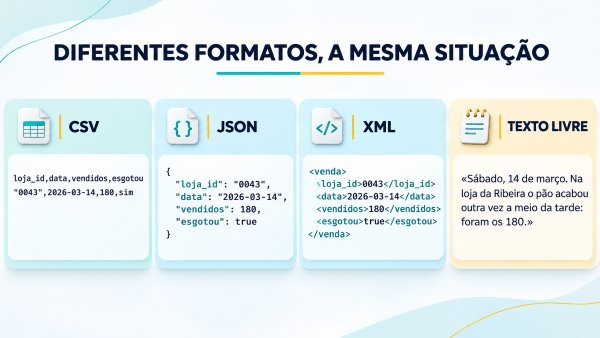

Os quatro blocos dizem o mesmo. O que muda é o trabalho necessário para chegar a uma tabela, e o que se perde ou ganha pelo caminho.

> **O formato não determina o significado, a qualidade nem a estrutura analítica.** Um ficheiro CSV pode conter lixo, e uma nota de texto pode conter a informação mais importante.

### CSV: uma tabela escrita em texto

Um ficheiro CSV (*comma-separated values*) é uma tabela guardada como texto simples. Cada linha do ficheiro é um registo, e a primeira costuma ter os nomes dos campos.

In [6]:
import io

texto_csv = '''loja_id,data,vendidos,esgotou
"0043",2026-03-14,180,sim
"0107",2026-03-14,391,não
'''
print(pd.read_csv(io.StringIO(texto_csv), dtype={"loja_id": str}, parse_dates=["data"]))

  loja_id       data  vendidos esgotou
0    0043 2026-03-14       180     sim
1    0107 2026-03-14       391     não


O CSV é simples e universal, e por isso mesmo guarda pouca informação: não diz o tipo de cada campo (daí o `dtype` e o `parse_dates`, como vimos no capítulo 2), nem a unidade, nem a codificação dos caracteres.

Também não há um único CSV. Em Portugal, as folhas de cálculo exportam com **ponto e vírgula** a separar os campos e **vírgula** nos decimais.

In [7]:
texto_pt = '''loja_id;data;chuva_mm;vendidos
0043;14/03/2026;2,4;180
0107;14/03/2026;0,0;391
'''
errado = pd.read_csv(io.StringIO(texto_pt))
print("Leitura por omissão:", errado.shape, "→ colunas:", list(errado.columns), "\n")

certo = pd.read_csv(io.StringIO(texto_pt), sep=";", decimal=",", dtype={"loja_id": str})
certo["data"] = pd.to_datetime(certo["data"], format="%d/%m/%Y")
print(certo, "\n")
print(certo.dtypes)

Leitura por omissão: (2, 1) → colunas: ['loja_id;data;chuva_mm;vendidos'] 

  loja_id       data  chuva_mm  vendidos
0    0043 2026-03-14       2.4       180
1    0107 2026-03-14       0.0       391 

loja_id                str
data        datetime64[us]
chuva_mm           float64
vendidos             int64
dtype: object


Lido sem indicações, o ficheiro fica com uma única coluna (ou, pior, com colunas partidas ao meio pelas vírgulas dos decimais). Abre sempre o ficheiro num editor de texto antes de o ler com código: bastam as cinco primeiras linhas para ver o separador, os decimais e o formato das datas.

## Dados semiestruturados

Nos dados **semiestruturados**, cada registo traz consigo os nomes dos seus campos, sob a forma de chaves ou de etiquetas. Isto permite duas coisas que uma tabela não permite: **campos opcionais** (um registo pode ter campos que outro não tem) e **aninhamento** (um campo pode conter uma lista ou outro registo).

### JSON: campos com nome e informação aninhada

In [8]:
import json

texto_json = '''
[
  {"loja_id": "0043", "data": "2026-03-14", "vendidos": 180, "esgotou": true,
   "ocorrencias": ["evento na zona", "fila à porta"], "hora_esgotou": "15:40",
   "gerente": {"nome": "Marta", "turno": "tarde"}},
  {"loja_id": "0107", "data": "2026-03-14", "vendidos": 391, "esgotou": false,
   "ocorrencias": [], "hora_esgotou": null,
   "gerente": {"nome": "Rui", "turno": "manhã"}},
  {"loja_id": "0212", "data": "2026-03-14", "vendidos": 204, "esgotou": false,
   "ocorrencias": ["caixa avariada"], "hora_esgotou": null}
]
'''
registos = json.loads(texto_json)
print("Campos do primeiro registo:", list(registos[0]))
print("Campos do terceiro registo:", list(registos[2]))

Campos do primeiro registo: ['loja_id', 'data', 'vendidos', 'esgotou', 'ocorrencias', 'hora_esgotou', 'gerente']
Campos do terceiro registo: ['loja_id', 'data', 'vendidos', 'esgotou', 'ocorrencias', 'hora_esgotou']


Três pormenores a notar:

- `"ocorrencias"` é uma **lista**: pode ter zero, um ou vários valores;
- `"gerente"` é um registo **dentro** de outro registo, e falta no terceiro;
- `null` marca um valor ausente, segundo uma regra combinada: aqui, o pão não esgotou, por isso não há hora.

Para chegar a uma tabela, o pandas «achata» os registos aninhados.

In [9]:
tabela = pd.json_normalize(registos)
tabela

,loja_id,data,vendidos,esgotou,ocorrencias,hora_esgotou,gerente.nome,gerente.turno
0,0043,2026-03-14,180,True,"[evento na zona, fila à porta]",15:40,Marta,tarde
1,0107,2026-03-14,391,False,[],NaN,Rui,manhã
2,0212,2026-03-14,204,False,[caixa avariada],NaN,NaN,NaN


O registo `gerente` transformou-se em duas colunas (`gerente.nome` e `gerente.turno`), com valores em falta na loja que não o tinha. Mas a coluna `ocorrencias` continua a ter **listas** dentro das células, o que viola a regra «uma célula, um valor».

### A decisão que o formato não toma por nós

Há pelo menos três formas de pôr uma lista numa tabela, e cada uma serve uma pergunta diferente.

In [10]:
opcao_a = tabela[["loja_id", "ocorrencias"]].explode("ocorrencias")
opcao_b = tabela[["loja_id"]].assign(n_ocorrencias=tabela["ocorrencias"].str.len())
opcao_c = tabela[["loja_id"]].assign(
    evento_na_zona=tabela["ocorrencias"].apply(lambda lista: "evento na zona" in lista),
    caixa_avariada=tabela["ocorrencias"].apply(lambda lista: "caixa avariada" in lista))

print("A. Uma linha por ocorrência\n", opcao_a, "\n")
print("B. Contar as ocorrências\n", opcao_b, "\n")
print("C. Uma coluna por ocorrência que interessa\n", opcao_c)

A. Uma linha por ocorrência
   loja_id     ocorrencias
0    0043  evento na zona
0    0043    fila à porta
1    0107             NaN
2    0212  caixa avariada 

B. Contar as ocorrências
   loja_id  n_ocorrencias
0    0043              2
1    0107              0
2    0212              1 

C. Uma coluna por ocorrência que interessa
   loja_id  evento_na_zona  caixa_avariada
0    0043            True           False
1    0107           False           False
2    0212           False            True


| Opção | Unidade de análise | Serve para | Cuidado |
| --- | --- | --- | --- |
| A. Uma linha por ocorrência | ocorrência | Contar quantas vezes acontece cada ocorrência | A loja `0043` aparece duas vezes: somar as vendas nesta tabela daria o dobro |
| B. Contar | loja e dia | Saber se foi um dia «agitado» | Perde-se **qual** foi a ocorrência |
| C. Uma coluna por ocorrência | loja e dia | Usar ocorrências específicas num modelo | É preciso decidir à partida quais interessam |

Nenhuma das três é a correta em geral. A escolha depende da pergunta, e é uma **decisão de quem analisa**: o formato não a toma.

### XML: a mesma ideia, com etiquetas

O XML organiza os dados com etiquetas de abertura e de fecho. É mais antigo e mais palavroso do que o JSON, e continua a ser comum em faturação eletrónica e na administração pública.

In [11]:
import xml.etree.ElementTree as ET

texto_xml = '''
<vendas>
  <venda><loja_id>0043</loja_id><data>2026-03-14</data><vendidos>180</vendidos></venda>
  <venda><loja_id>0107</loja_id><data>2026-03-14</data><vendidos>391</vendidos></venda>
</vendas>
'''
raiz = ET.fromstring(texto_xml)
pd.DataFrame([{campo.tag: campo.text for campo in venda} for venda in raiz])

,loja_id,data,vendidos
0,0043,2026-03-14,180
1,0107,2026-03-14,391


Repara que todos os valores chegam como texto, incluindo `vendidos`. Como no CSV, os tipos têm de ser atribuídos por quem lê.

### HTML: etiquetas que organizam um documento

O HTML das páginas web também usa etiquetas, mas com outro objetivo: descrevem **elementos de um documento** (títulos, parágrafos, tabelas), e não variáveis. Quem recolhe dados de uma página tem de descobrir que partes do documento representam observações.

In [12]:
from html.parser import HTMLParser

pagina = '''
<h1>Padarias do Rio – lojas</h1>
<p>Atualizado a 14 de março.</p>
<h2>Loja 0043</h2>
<p>Zona: Ribeira</p>
<p>Pão do dia: esgotado</p>
<h2>Loja 0107</h2>
<p>Zona: Estação</p>
<p>Pão do dia: disponível</p>
'''


class LeitorDeLojas(HTMLParser):
    """Cria um registo por cada título <h2> e junta-lhe os parágrafos «campo: valor» que se seguem."""

    def __init__(self):
        super().__init__()
        self.registos, self.etiqueta = [], None

    def handle_starttag(self, etiqueta, atributos):
        self.etiqueta = etiqueta

    def handle_data(self, texto):
        texto = texto.strip()
        if self.etiqueta == "h2" and texto:
            self.registos.append({"loja_id": texto.replace("Loja ", "")})
        elif self.etiqueta == "p" and ":" in texto and self.registos:
            campo, valor = texto.split(":", 1)
            self.registos[-1][campo.strip()] = valor.strip()


leitor = LeitorDeLojas()
leitor.feed(pagina)
pd.DataFrame(leitor.registos)

,loja_id,Zona,Pão do dia
0,0043,Ribeira,esgotado
1,0107,Estação,disponível


O programa teve de assumir três coisas que a página não garante: que cada loja começa num `<h2>`, que os campos vêm em parágrafos com dois pontos e que o primeiro parágrafo («Atualizado a…») não pertence a nenhuma loja. Se o sítio mudar de aspeto, a recolha deixa de funcionar, por vezes sem dar erro. Antes de recolher dados de uma página, confirma também que os termos de utilização o permitem.

## Dados não estruturados e conteúdo misto

Dados **não estruturados** não têm uma disposição de variáveis definida à partida: texto livre, imagens, áudio, vídeo. A informação está lá, mas é preciso **extraí-la**.

Os gerentes das lojas escrevem uma nota no fecho do dia.

In [13]:
import re

notas = pd.DataFrame({"loja_id": ["0043", "0107", "0212", "0305"], "nota": [
    "Pão esgotado às 15h40. Feira do livro trouxe muita gente, fila à porta desde as 11h.",
    "Dia calmo. Sobraram uns 9 pães, foram para a associação do bairro.",
    "caixa avariada de manhã!! vendas apontadas à mão. sobraram 16",
    "Esgotou por volta das 17h10, choveu a tarde toda."]})


def extrair(nota):
    """Extrai três variáveis de uma nota de texto livre."""
    hora = re.search(r"esgot\w+[^\d]*(\d{1,2})h(\d{2})", nota, flags=re.I)
    sobras = re.search(r"sobraram\D*(\d+)", nota, flags=re.I)
    return pd.Series({"hora_esgotou": f"{hora.group(1)}:{hora.group(2)}" if hora else None,
                      "sobras": int(sobras.group(1)) if sobras else None,
                      "menciona_avaria": bool(re.search(r"avaria", nota, flags=re.I))})


pd.concat([notas, notas["nota"].apply(extrair)], axis=1)

,loja_id,nota,hora_esgotou,sobras,menciona_avaria
0,0043,Pão esgotado às 15h40. Feira do livro trouxe m...,15:40,NaN,False
1,0107,"Dia calmo. Sobraram uns 9 pães, foram para a a...",NaN,9.0,False
2,0212,caixa avariada de manhã!! vendas apontadas à m...,NaN,16.0,True
3,0305,"Esgotou por volta das 17h10, choveu a tarde toda.",17:10,NaN,False


Com três expressões regulares, o texto livre deu três colunas. Mas repara no que ficou por extrair: a feira do livro, a fila, a chuva, o destino das sobras. Cada extração é uma **interpretação**: outro analista escolheria outras variáveis, e uma nota escrita de forma ligeiramente diferente («ficaram 9 pães») escaparia à regra.

### Conteúdo misto

Muitas fontes juntam partes com graus de organização diferentes. Uma mensagem de correio eletrónico tem um cabeçalho estruturado e um corpo em texto livre.

In [14]:
from email import message_from_string

mensagem = message_from_string('''From: loja0043@padariasdorio.example
To: producao@padariasdorio.example
Date: Sat, 14 Mar 2026 18:05:00 +0000
Subject: Fecho do dia - loja 0043

Boa tarde. O pão voltou a acabar cedo, antes das 16h.
Para sábado que vem pedia mais 40 unidades.
''')
print("ESTRUTURADO")
for campo in ("From", "Date", "Subject"):
    print(f"  {campo}: {mensagem[campo]}")
print("\nNÃO ESTRUTURADO")
print(" ", mensagem.get_payload().strip().replace("\n", "\n  "))

ESTRUTURADO
  From: loja0043@padariasdorio.example
  Date: Sat, 14 Mar 2026 18:05:00 +0000
  Subject: Fecho do dia - loja 0043

NÃO ESTRUTURADO
  Boa tarde. O pão voltou a acabar cedo, antes das 16h.
  Para sábado que vem pedia mais 40 unidades.


O cabeçalho lê-se sem ambiguidade. O pedido de «mais 40 unidades», que é a informação mais útil para a decisão de produção, está no corpo.

### A maior parte dos dados não está em tabelas

As estimativas da indústria apontam para que **80% a 90% dos dados das empresas sejam não estruturados**: mensagens, documentos, imagens, gravações. O valor exato depende do que cada organização guarda e de como mede, por isso deve ser lido como uma ordem de grandeza, e não como uma proporção universal. A conclusão prática mantém-se: quem só sabe trabalhar com tabelas ignora a maior parte da informação disponível.

## Comparar as três organizações

| Organização | Vantagens | Desvantagens | Onde se guarda |
| --- | --- | --- | --- |
| **Estruturada** | Campos consistentes; filtrar e agregar é fácil; quase todas as ferramentas a leem | Mudar o esquema exige coordenação; dados aninhados obrigam a criar mais tabelas | Folhas de cálculo, bases de dados relacionais, armazéns de dados |
| **Semiestruturada** | Campos opcionais e aninhamento; registos flexíveis; converte-se em tabelas | Campos e tipos variáveis precisam de regras; as listas aninhadas complicam as comparações | Ficheiros JSON e XML, bases de dados de documentos |
| **Não estruturada** | Preserva o detalhe e o contexto; permite analisar texto, imagem e áudio | Extrair exige ferramentas e conhecimento; a interpretação e a verificação da qualidade pedem cuidado | Ficheiros, armazenamento de objetos, lagos de dados |

## Exercícios

### `Exercício 1` – Que organização é?

Classifica cada fonte como estruturada, semiestruturada, não estruturada ou mista:

1. A tabela de clientes numa base de dados relacional.
2. As gravações das chamadas para a linha de apoio.
3. A resposta de uma API de meteorologia, em JSON.
4. Uma fatura em PDF digitalizada.
5. Uma publicação numa rede social, com texto, data, número de gostos e uma fotografia.
6. Um ficheiro de registos de um servidor, com uma linha por pedido.

<details>
<summary><b>Ver uma solução possível</b></summary>

1. Estruturada.
2. Não estruturada.
3. Semiestruturada.
4. Não estruturada (é uma imagem), embora o documento original tivesse campos bem definidos.
5. Mista: a data e os gostos são estruturados; o texto e a fotografia não.
6. Semiestruturada: cada linha segue um padrão, mas a mensagem de cada pedido costuma ser texto livre.

</details>

### `Exercício 2` – Escrever um esquema

Escreve o esquema (campo, tipo e regra) da tabela `meteo` e da tabela `eventos`. Depois acrescenta uma regra à função `verificar_esquema`: «não há duas linhas com a mesma loja e a mesma data».

In [15]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

`meteo`: `data` (data, única, sem falhas entre a primeira e a última); `chuva_mm` (decimal, maior ou igual a 0).

`eventos`: `data` (data); `zona` (texto, tem de existir no cadastro das lojas); `evento` (texto, não vazio); a combinação `data` + `zona` é única.

```python
repetidas = vendas.duplicated(["loja_id", "data"], keep=False)
print("Linhas com loja e data repetidas:", int(repetidas.sum()))
```

Dentro da função, a regra seria `"loja e data únicas": ~tabela.duplicated(["loja_id", "data"], keep=False)`.

</details>

### `Exercício 3` – De JSON para tabela

Com a lista `registos`, constrói uma tabela com uma linha por loja e as colunas `loja_id`, `vendidos`, `turno_do_gerente` e `teve_ocorrencias` (verdadeiro ou falso). O que fazes à loja que não tem gerente?

In [16]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
t = pd.json_normalize(registos)
resultado = pd.DataFrame({"loja_id": t["loja_id"], "vendidos": t["vendidos"],
                          "turno_do_gerente": t["gerente.turno"],
                          "teve_ocorrencias": t["ocorrencias"].str.len() > 0})
resultado
```

A loja `0212` fica com o turno em falta. É a opção honesta: não sabemos qual foi. Preencher com «manhã» por ser o mais frequente seria inventar um dado.

</details>

### `Exercício 4` – Melhorar a extração

A nota «Ficaram 9 pães no fim do dia.» não é apanhada pela função `extrair`. Altera a expressão regular das sobras para a apanhar e testa com as notas anteriores. Consegues pensar numa nota que continue a escapar?

In [17]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
padrao = r"(?:sobraram|ficaram|restaram)\D*(\d+)"
for nota in list(notas["nota"]) + ["Ficaram 9 pães no fim do dia."]:
    achado = re.search(padrao, nota, flags=re.I)
    print(achado.group(1) if achado else None, "|", nota[:50])
```

Continuam a escapar notas como «sobrou meia dúzia», «não sobrou nada» ou «ficaram 2 clientes sem pão» (que seria apanhada por engano). A extração por regras nunca está completa: é preciso ler uma amostra das notas para saber quanto falha.

</details>

## Verifica o que aprendeste

- [ ] Sei distinguir dados estruturados, semiestruturados e não estruturados, e dar exemplos.
- [ ] Sei o que é um esquema e como verificá-lo com código.
- [ ] Sei ler um CSV com separador e decimais portugueses.
- [ ] Sei converter JSON aninhado numa tabela e decidir o que fazer a uma lista.
- [ ] Sei porque a recolha de dados de páginas HTML é frágil.
- [ ] Sei extrair variáveis de texto livre e reconhecer os limites dessa extração.
- [ ] Sei comparar as vantagens e as desvantagens das três organizações.

## Leitura recomendada

- https://pandas.pydata.org/docs/user_guide/io.html
- https://www.json.org/json-pt.html
- https://docs.python.org/3/library/re.html
- https://www.ibm.com/think/topics/unstructured-data